In [35]:
# CAREER NAVIGATOR
# ANN - STUDENT PLACEMENT PREDICTION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
import random
import warnings
import tensorflow as tf

from pathlib import Path

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print("TensorFlow Version:", tf.__version__)
print("GPU Devices:", tf.config.list_physical_devices("GPU"))
print("Libraries imported successfully!")

TensorFlow Version: 2.21.0
GPU Devices: []
Libraries imported successfully!


In [36]:
PROJECT_ROOT = Path.cwd().parent

PROCESSED_DIR = PROJECT_ROOT / "dataset" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = PROJECT_ROOT / "reports" / "evaluation"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Project Directory:", PROJECT_ROOT)
print("Processed Data:", PROCESSED_DIR)
print("Model Directory:", MODEL_DIR)
print("Report Directory:", REPORT_DIR)

Project Directory: d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator
Processed Data: d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\dataset\processed
Model Directory: d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\models
Report Directory: d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\reports\evaluation


In [37]:
# Load input features

X_train = np.load(PROCESSED_DIR / "X_train.npy").astype("float32")
X_val = np.load(PROCESSED_DIR / "X_val.npy").astype("float32")
X_test = np.load(PROCESSED_DIR / "X_test.npy").astype("float32")

# Load placement targets

y_train = np.load(
    PROCESSED_DIR / "y_train_placement.npy"
).astype("float32")

y_val = np.load(
    PROCESSED_DIR / "y_val_placement.npy"
).astype("float32")

y_test = np.load(
    PROCESSED_DIR / "y_test_placement.npy"
).astype("float32")

print("Dataset loaded successfully!")

print("\nInput dimensions:")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nTarget dimensions:")
print("Training:", y_train.shape)
print("Validation:", y_val.shape)
print("Testing:", y_test.shape)

Dataset loaded successfully!

Input dimensions:
Training: (10500, 65)
Validation: (2250, 65)
Testing: (2250, 65)

Target dimensions:
Training: (10500,)
Validation: (2250,)
Testing: (2250,)


,Class,Count,Percentage
0,Not Placed,6672,63.54
1,Placed,3828,36.46


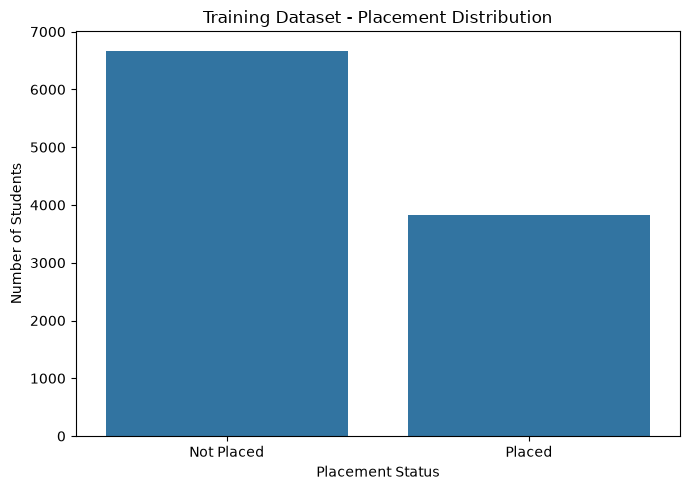

In [38]:
placement_distribution = pd.DataFrame({
    "Class": ["Not Placed", "Placed"],
    "Count": [
        np.sum(y_train == 0),
        np.sum(y_train == 1)
    ]
})

placement_distribution["Percentage"] = (
    placement_distribution["Count"] /
    len(y_train) * 100
)

display(placement_distribution.round(2))

plt.figure(figsize=(7, 5))

sns.barplot(
    data=placement_distribution,
    x="Class",
    y="Count"
)

plt.title("Training Dataset - Placement Distribution")
plt.xlabel("Placement Status")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

In [39]:
placement_ann = Sequential([
    Input(shape=(X_train.shape[1],)),

    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),

    Dropout(0.30),

    Dense(1, activation="sigmoid")
])

placement_ann.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

placement_ann.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_16 (Dense)                │ (None, 128)            │         8,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,817 (73.50 KB)

 Trainable params: 18,817 (73.50 KB)

 Non-trainable params: 0 (0.00 B)

In [40]:
callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=str(MODEL_DIR / "ann_placement_best.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=0.00001,
        verbose=1
    )
]

print("Training callbacks configured successfully!")

Training callbacks configured successfully!


In [41]:
history = placement_ann.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

print("\nANN training completed!")
print("Total epochs:", len(history.history["loss"]))
print("Best validation loss:", min(history.history["val_loss"]))

Epoch 1/100
306/329 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6373 - loss: 0.6446
Epoch 1: val_loss improved from None to 0.63198, saving model to d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\models\ann_placement_best.keras

Epoch 1: finished saving model to d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\models\ann_placement_best.keras
329/329 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6367 - loss: 0.6448 - val_accuracy: 0.6467 - val_loss: 0.6320 - learning_rate: 0.0010
Epoch 2/100
300/329 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6539 - loss: 0.6285
Epoch 2: val_loss improved from 0.63198 to 0.63115, saving model to d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\models\ann_placement_best.keras

Epoch 2: finished saving model to d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\models\ann_placement_best.keras
329/329 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6526 - loss: 0.6296 - val_a

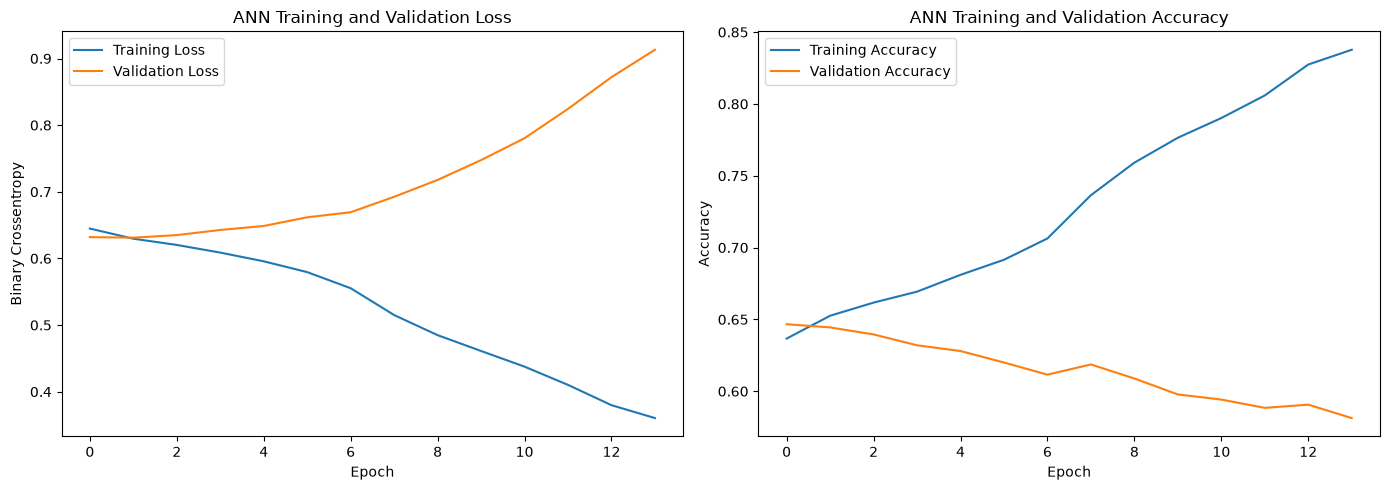

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    history.history["loss"],
    label="Training Loss"
)

axes[0].plot(
    history.history["val_loss"],
    label="Validation Loss"
)

axes[0].set_title("ANN Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Crossentropy")
axes[0].legend()

axes[1].plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

axes[1].plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

axes[1].set_title("ANN Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

In [43]:
placement_probabilities = placement_ann.predict(
    X_val,
    verbose=0
).ravel()

# Default classification threshold

DEFAULT_THRESHOLD = 0.5

placement_predictions = (
    placement_probabilities >= DEFAULT_THRESHOLD
).astype(int)

print("Validation predictions generated!")

print("\nSample probabilities:")
print(placement_probabilities[:10])

print("\nSample predicted classes:")
print(placement_predictions[:10])

Validation predictions generated!

Sample probabilities:
[0.29377925 0.3720542  0.33158776 0.4110899  0.4896546  0.19081244
 0.498551   0.31301785 0.2591272  0.4460133 ]

Sample predicted classes:
[0 0 0 0 0 0 0 0 0 0]


In [44]:
placement_ann_results = {
    "Model": "ANN",
    "Accuracy": accuracy_score(
        y_val, placement_predictions
    ),
    "Precision": precision_score(
        y_val, placement_predictions,
        zero_division=0
    ),
    "Recall": recall_score(
        y_val, placement_predictions,
        zero_division=0
    ),
    "Binary_F1": f1_score(
        y_val, placement_predictions,
        zero_division=0
    ),
    "Macro_F1": f1_score(
        y_val, placement_predictions,
        average="macro"
    ),
    "ROC_AUC": roc_auc_score(
        y_val, placement_probabilities
    )
}

placement_ann_results_df = pd.DataFrame([
    placement_ann_results
])

display(placement_ann_results_df.round(4))

,Model,Accuracy,Precision,Recall,Binary_F1,Macro_F1,ROC_AUC
0,ANN,0.6444,0.5338,0.1927,0.2832,0.5234,0.633


In [45]:
placement_report = classification_report(
    y_val,
    placement_predictions,
    labels=[0, 1],
    target_names=["Not Placed", "Placed"],
    output_dict=True,
    zero_division=0
)

placement_report_df = pd.DataFrame(
    placement_report
).transpose()

display(placement_report_df.round(4))

placement_report_df.to_csv(
    REPORT_DIR / "ann_placement_classification_report.csv"
)

print("Classification report saved!")

,precision,recall,f1-score,support
Not Placed,0.6612,0.9035,0.7636,1430.0000
Placed,0.5338,0.1927,0.2832,820.0000
accuracy,0.6444,0.6444,0.6444,0.6444
macro avg,0.5975,0.5481,0.5234,2250.0000
weighted avg,0.6148,0.6444,0.5885,2250.0000


Classification report saved!


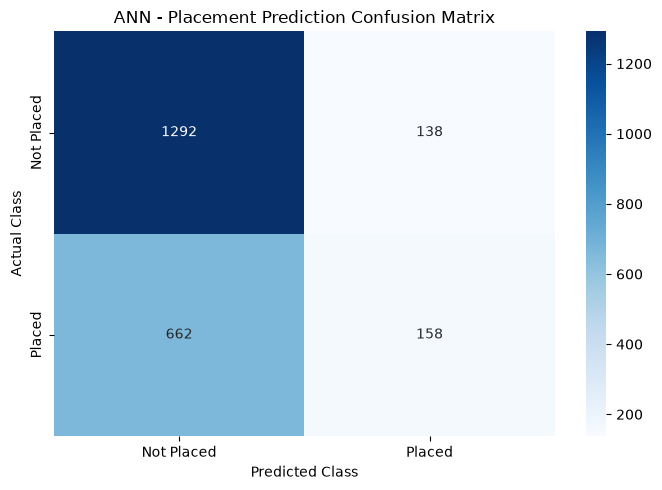

In [46]:
cm = confusion_matrix(
    y_val,
    placement_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Placed", "Placed"],
    yticklabels=["Not Placed", "Placed"]
)

plt.title("ANN - Placement Prediction Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

In [47]:
baseline_path = (
    REPORT_DIR / "baseline_classification_results.csv"
)

if not baseline_path.exists():
    raise FileNotFoundError(
        f"Baseline results not found: {baseline_path}. "
        "Run and save the results in 04_baseline_models.ipynb first."
    )

baseline_df = pd.read_csv(baseline_path)

baseline_placement = baseline_df[
    baseline_df["Task"] == "Placement"
].copy()

print("Baseline placement results loaded successfully!")

display(baseline_placement)

Baseline placement results loaded successfully!


,Task,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,F1_Weighted,ROC_AUC
6,Placement,Decision Tree,0.574667,0.538849,0.538453,0.538608,0.573577,0.538453
7,Placement,Logistic Regression,0.649333,0.608057,0.553757,0.530772,0.594717,0.648792
8,Placement,Random Forest,0.651556,0.617394,0.549002,0.517493,0.586446,0.632382


In [48]:
# Prepare baseline comparison

comparison = baseline_placement[
    ["Model", "Accuracy", "F1_Macro", "ROC_AUC"]
].copy()

comparison.rename(
    columns={"F1_Macro": "Macro_F1"},
    inplace=True
)

# Prepare ANN comparison

ann_comparison = pd.DataFrame([{
    "Model": "ANN",
    "Accuracy": placement_ann_results["Accuracy"],
    "Macro_F1": placement_ann_results["Macro_F1"],
    "ROC_AUC": placement_ann_results["ROC_AUC"]
}])

# Combine all results

placement_comparison = pd.concat(
    [comparison, ann_comparison],
    ignore_index=True
)

placement_comparison = placement_comparison.sort_values(
    "Macro_F1",
    ascending=False
).reset_index(drop=True)

print("PLACEMENT - BASELINE VS ANN")
print("=" * 65)

display(placement_comparison.round(4))

PLACEMENT - BASELINE VS ANN


,Model,Accuracy,Macro_F1,ROC_AUC
0,Decision Tree,0.5747,0.5386,0.5385
1,Logistic Regression,0.6493,0.5308,0.6488
2,ANN,0.6444,0.5234,0.6330
3,Random Forest,0.6516,0.5175,0.6324


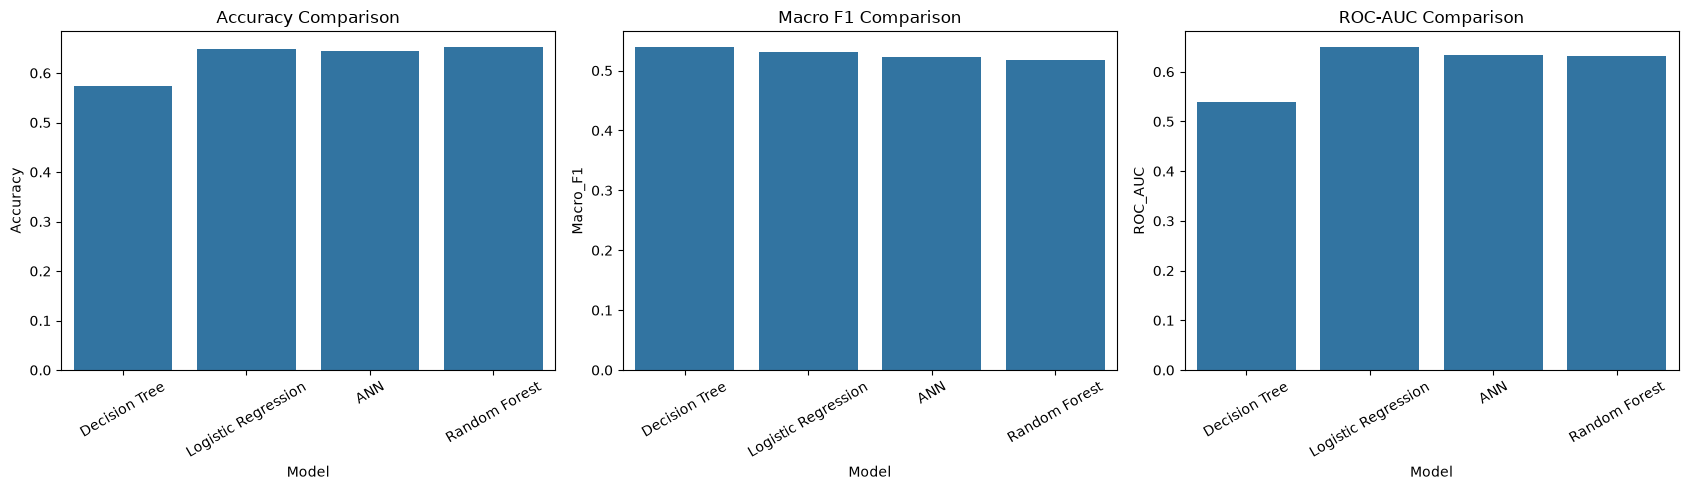

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

metrics = [
    ("Accuracy", "Accuracy Comparison"),
    ("Macro_F1", "Macro F1 Comparison"),
    ("ROC_AUC", "ROC-AUC Comparison")
]

for ax, (metric, title) in zip(axes, metrics):

    sns.barplot(
        data=placement_comparison,
        x="Model",
        y=metric,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Model")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [50]:
threshold_results = []

thresholds = np.arange(0.20, 0.71, 0.05)

for threshold in thresholds:

    predictions = (
        placement_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,

        "Accuracy": accuracy_score(
            y_val, predictions
        ),

        "Precision": precision_score(
            y_val, predictions,
            zero_division=0
        ),

        "Recall": recall_score(
            y_val, predictions,
            zero_division=0
        ),

        "Macro_F1": f1_score(
            y_val, predictions,
            average="macro"
        ),

        "Binary_F1": f1_score(
            y_val, predictions,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Accuracy,Precision,Recall,Macro_F1,Binary_F1
0,0.20,0.4067,0.3787,0.9805,0.3445,0.5464
1,0.25,0.4476,0.3908,0.9232,0.4180,0.5491
2,0.30,0.5062,0.4124,0.8354,0.5010,0.5522
3,0.35,0.5582,0.4351,0.7110,0.5575,0.5398
4,0.40,0.6062,0.4660,0.5512,0.5890,0.5050
5,0.45,0.6302,0.4902,0.3671,0.5742,0.4198
6,0.50,0.6444,0.5338,0.1927,0.5234,0.2832
7,0.55,0.6351,0.4963,0.0817,0.4544,0.1403
8,0.60,0.6360,0.5094,0.0329,0.4180,0.0619
9,0.65,0.6387,0.7333,0.0134,0.4023,0.0263


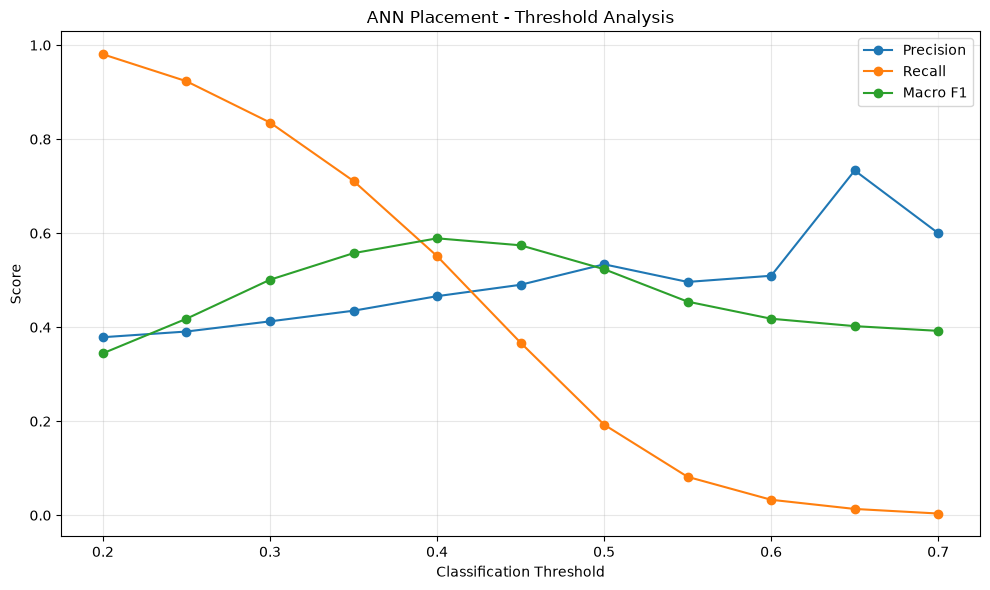

In [51]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Macro_F1"],
    marker="o",
    label="Macro F1"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("ANN Placement - Threshold Analysis")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [52]:
best_threshold_row = threshold_df.loc[
    threshold_df["Macro_F1"].idxmax()
]

best_threshold = float(
    best_threshold_row["Threshold"]
)

print("BEST THRESHOLD ANALYSIS")
print("=" * 50)

print("Best Threshold:", best_threshold)
print("Accuracy:", round(best_threshold_row["Accuracy"], 4))
print("Precision:", round(best_threshold_row["Precision"], 4))
print("Recall:", round(best_threshold_row["Recall"], 4))
print("Macro F1:", round(best_threshold_row["Macro_F1"], 4))

BEST THRESHOLD ANALYSIS
Best Threshold: 0.39999999999999997
Accuracy: 0.6062
Precision: 0.466
Recall: 0.5512
Macro F1: 0.589


In [53]:
# Save trained ANN

placement_ann.save(
    MODEL_DIR / "ann_placement_final.keras"
)

# Save training history

pd.DataFrame(
    history.history
).to_csv(
    REPORT_DIR / "ann_placement_training_history.csv",
    index=False
)

# Save ANN metrics

placement_ann_results_df.to_csv(
    REPORT_DIR / "ann_placement_metrics.csv",
    index=False
)

# Save baseline vs ANN comparison

placement_comparison.to_csv(
    REPORT_DIR / "placement_baseline_ann_comparison.csv",
    index=False
)

# Save threshold analysis

threshold_df.to_csv(
    REPORT_DIR / "ann_placement_threshold_analysis.csv",
    index=False
)

# Save selected validation threshold

with open(
    REPORT_DIR / "ann_placement_best_threshold.json",
    "w"
) as file:
    json.dump(
        {
            "threshold": best_threshold,
            "selection_metric": "validation_macro_f1",
            "validation_macro_f1": float(
                best_threshold_row["Macro_F1"]
            )
        },
        file,
        indent=4
    )

print("All ANN placement artifacts saved successfully!")

All ANN placement artifacts saved successfully!


In [54]:
ann_artifacts = [
    MODEL_DIR / "ann_placement_best.keras",
    MODEL_DIR / "ann_placement_final.keras",

    REPORT_DIR / "ann_placement_training_history.csv",
    REPORT_DIR / "ann_placement_metrics.csv",
    REPORT_DIR / "ann_placement_classification_report.csv",
    REPORT_DIR / "placement_baseline_ann_comparison.csv",
    REPORT_DIR / "ann_placement_threshold_analysis.csv",
    REPORT_DIR / "ann_placement_best_threshold.json"
]

print("ANN PLACEMENT - ARTIFACT VERIFICATION")
print("=" * 65)

missing_artifacts = []

for artifact in ann_artifacts:

    status = artifact.exists()

    print(
        f"{artifact.name}:",
        "FOUND" if status else "MISSING"
    )

    if not status:
        missing_artifacts.append(artifact.name)

print("\nMissing artifacts:", missing_artifacts)

assert not missing_artifacts, "Some ANN artifacts are missing!"

print("\nALL ANN PLACEMENT ARTIFACTS VERIFIED!")

ANN PLACEMENT - ARTIFACT VERIFICATION
ann_placement_best.keras: FOUND
ann_placement_final.keras: FOUND
ann_placement_training_history.csv: FOUND
ann_placement_metrics.csv: FOUND
ann_placement_classification_report.csv: FOUND
placement_baseline_ann_comparison.csv: FOUND
ann_placement_threshold_analysis.csv: FOUND
ann_placement_best_threshold.json: FOUND

Missing artifacts: []

ALL ANN PLACEMENT ARTIFACTS VERIFIED!


In [55]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train.astype(int))

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train.astype(int)
)

class_weight_dict = {
    int(cls): float(weight)
    for cls, weight in zip(classes, class_weights)
}

print("CLASS WEIGHTS")
print("=" * 40)

for cls, weight in class_weight_dict.items():
    label = "Not Placed" if cls == 0 else "Placed"
    print(f"{label}: {weight:.4f}")

CLASS WEIGHTS
Not Placed: 0.7869
Placed: 1.3715


In [56]:
weighted_placement_ann = Sequential([
    Input(shape=(X_train.shape[1],)),

    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),

    Dropout(0.30),

    Dense(1, activation="sigmoid")
])

weighted_placement_ann.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

weighted_placement_ann.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_20 (Dense)                │ (None, 128)            │         8,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,817 (73.50 KB)

 Trainable params: 18,817 (73.50 KB)

 Non-trainable params: 0 (0.00 B)

In [57]:
weighted_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=str(MODEL_DIR / "ann_placement_weighted_best.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=0.00001,
        verbose=1
    )
]

print("Weighted ANN callbacks configured!")

Weighted ANN callbacks configured!


In [58]:
weighted_history = weighted_placement_ann.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=weighted_callbacks,
    verbose=1
)

print("\nClass-weighted ANN training completed!")
print("Epochs trained:", len(weighted_history.history["loss"]))
print("Best validation loss:", min(weighted_history.history["val_loss"]))


Epoch 1/100
320/329 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5806 - loss: 0.6785
Epoch 1: val_loss improved from None to 0.66846, saving model to d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\models\ann_placement_weighted_best.keras

Epoch 1: finished saving model to d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\models\ann_placement_weighted_best.keras
329/329 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5803 - loss: 0.6790 - val_accuracy: 0.6018 - val_loss: 0.6685 - learning_rate: 0.0010
Epoch 2/100
329/329 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6104 - loss: 0.6631
Epoch 2: val_loss did not improve from 0.66846
329/329 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6104 - loss: 0.6631 - val_accuracy: 0.5987 - val_loss: 0.6733 - learning_rate: 0.0010
Epoch 3/100
325/329 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6165 - loss: 0.6552
Epoch 3: val_loss did not improve from 0.66846
329/329 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - ac

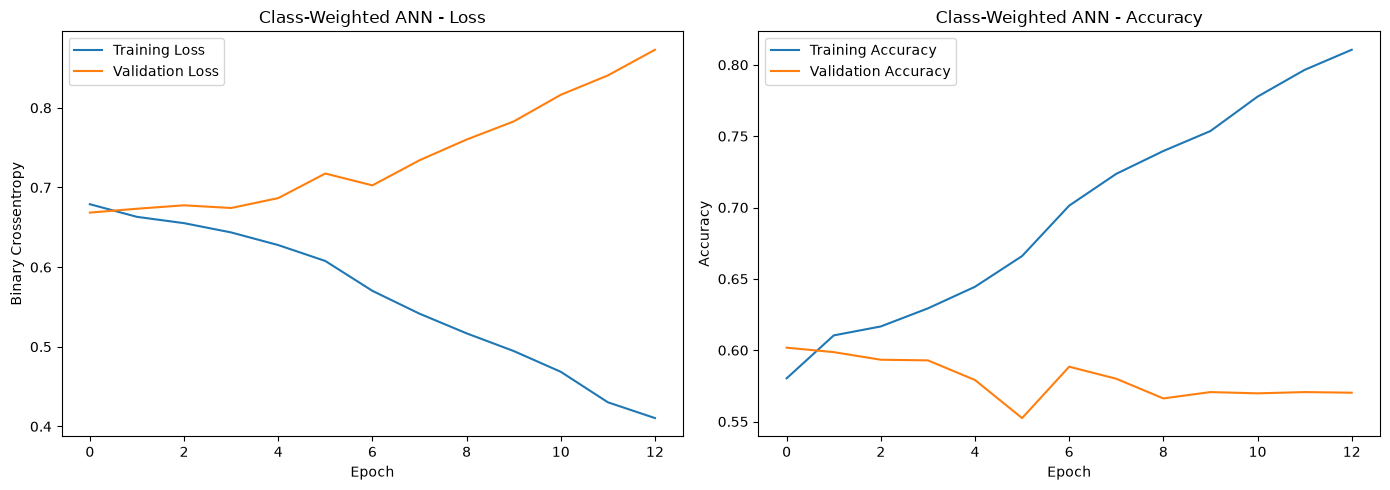

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    weighted_history.history["loss"],
    label="Training Loss"
)
axes[0].plot(
    weighted_history.history["val_loss"],
    label="Validation Loss"
)
axes[0].set_title("Class-Weighted ANN - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Crossentropy")
axes[0].legend()

axes[1].plot(
    weighted_history.history["accuracy"],
    label="Training Accuracy"
)
axes[1].plot(
    weighted_history.history["val_accuracy"],
    label="Validation Accuracy"
)
axes[1].set_title("Class-Weighted ANN - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

In [60]:
weighted_probabilities = weighted_placement_ann.predict(
    X_val,
    verbose=0
).ravel()

weighted_predictions = (
    weighted_probabilities >= 0.5
).astype(int)

print("Weighted ANN predictions generated!")

Weighted ANN predictions generated!


In [61]:
weighted_results = {
    "Model": "Class-Weighted ANN",
    "Accuracy": accuracy_score(y_val, weighted_predictions),
    "Precision": precision_score(
        y_val, weighted_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_val, weighted_predictions, zero_division=0
    ),
    "Binary_F1": f1_score(
        y_val, weighted_predictions, zero_division=0
    ),
    "Macro_F1": f1_score(
        y_val, weighted_predictions, average="macro"
    ),
    "ROC_AUC": roc_auc_score(
        y_val, weighted_probabilities
    )
}

weighted_results_df = pd.DataFrame([weighted_results])

display(weighted_results_df.round(4))

print("\nClassification Report")

print(classification_report(
    y_val,
    weighted_predictions,
    labels=[0, 1],
    target_names=["Not Placed", "Placed"],
    zero_division=0
))

,Model,Accuracy,Precision,Recall,Binary_F1,Macro_F1,ROC_AUC
0,Class-Weighted ANN,0.6018,0.4665,0.6463,0.5419,0.5949,0.642



Classification Report
              precision    recall  f1-score   support

  Not Placed       0.74      0.58      0.65      1430
      Placed       0.47      0.65      0.54       820

    accuracy                           0.60      2250
   macro avg       0.60      0.61      0.59      2250
weighted avg       0.64      0.60      0.61      2250



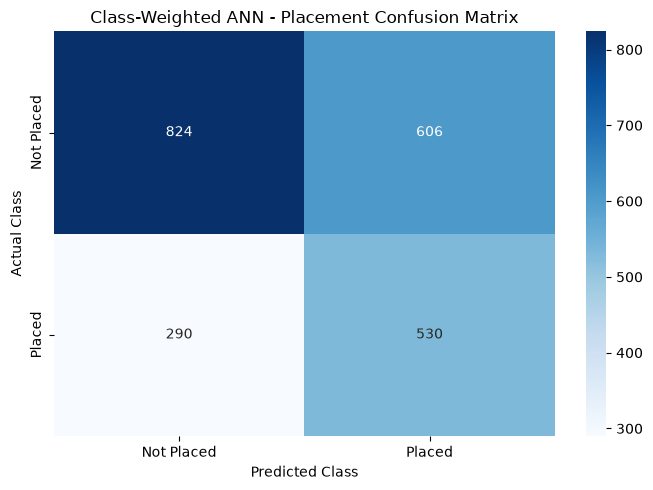

In [62]:
cm = confusion_matrix(
    y_val,
    weighted_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Placed", "Placed"],
    yticklabels=["Not Placed", "Placed"]
)

plt.title("Class-Weighted ANN - Placement Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

In [63]:
# Original ANN
original_ann_row = {
    "Model": "Original ANN",
    "Accuracy": placement_ann_results["Accuracy"],
    "Precision": placement_ann_results["Precision"],
    "Recall": placement_ann_results["Recall"],
    "Macro_F1": placement_ann_results["Macro_F1"],
    "ROC_AUC": placement_ann_results["ROC_AUC"]
}

# Class-weighted ANN
weighted_ann_row = {
    "Model": "Class-Weighted ANN",
    "Accuracy": weighted_results["Accuracy"],
    "Precision": weighted_results["Precision"],
    "Recall": weighted_results["Recall"],
    "Macro_F1": weighted_results["Macro_F1"],
    "ROC_AUC": weighted_results["ROC_AUC"]
}

# Baseline models
baseline_comparison = baseline_placement[
    ["Model", "Accuracy", "Precision_Macro",
     "Recall_Macro", "F1_Macro", "ROC_AUC"]
].copy()

baseline_comparison = baseline_comparison.rename(columns={
    "Precision_Macro": "Precision",
    "Recall_Macro": "Recall",
    "F1_Macro": "Macro_F1"
})

# Combine
placement_final_comparison = pd.concat(
    [
        baseline_comparison,
        pd.DataFrame([original_ann_row]),
        pd.DataFrame([weighted_ann_row])
    ],
    ignore_index=True
)

placement_final_comparison = placement_final_comparison.sort_values(
    "Macro_F1",
    ascending=False
).reset_index(drop=True)

display(placement_final_comparison.round(4))

,Model,Accuracy,Precision,Recall,Macro_F1,ROC_AUC
0,Class-Weighted ANN,0.6018,0.4665,0.6463,0.5949,0.6420
1,Decision Tree,0.5747,0.5388,0.5385,0.5386,0.5385
2,Logistic Regression,0.6493,0.6081,0.5538,0.5308,0.6488
3,Original ANN,0.6444,0.5338,0.1927,0.5234,0.6330
4,Random Forest,0.6516,0.6174,0.5490,0.5175,0.6324


,Experiment,Accuracy,Recall,Macro_F1,ROC_AUC
0,Original ANN,0.6444,0.1927,0.5234,0.633
1,Class-Weighted ANN,0.6018,0.6463,0.5949,0.642


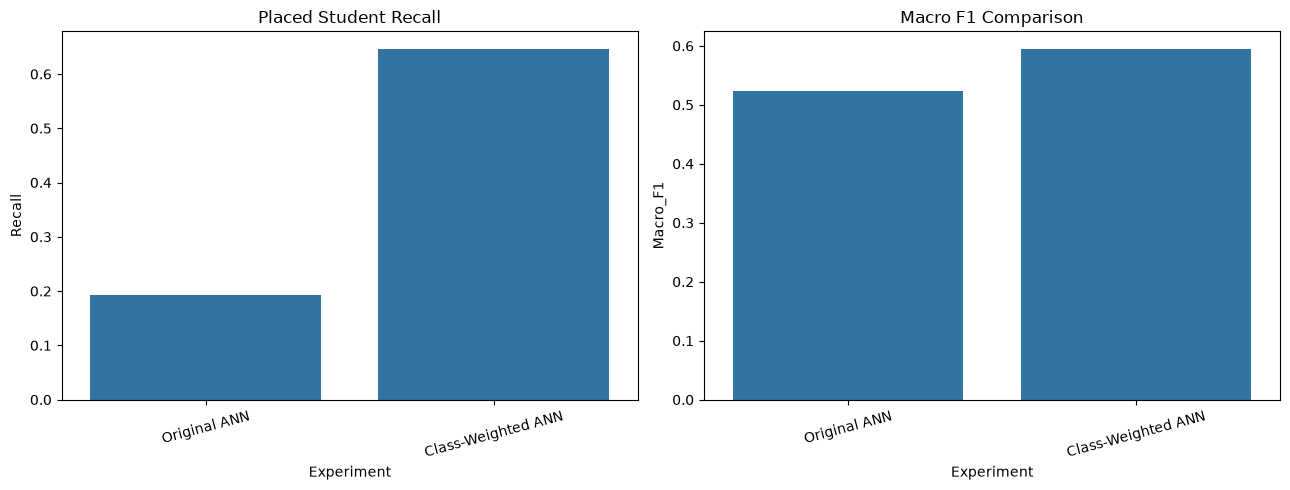

In [64]:
ann_experiment_comparison = pd.DataFrame([
    {
        "Experiment": "Original ANN",
        "Accuracy": placement_ann_results["Accuracy"],
        "Recall": placement_ann_results["Recall"],
        "Macro_F1": placement_ann_results["Macro_F1"],
        "ROC_AUC": placement_ann_results["ROC_AUC"]
    },
    {
        "Experiment": "Class-Weighted ANN",
        "Accuracy": weighted_results["Accuracy"],
        "Recall": weighted_results["Recall"],
        "Macro_F1": weighted_results["Macro_F1"],
        "ROC_AUC": weighted_results["ROC_AUC"]
    }
])

display(ann_experiment_comparison.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=ann_experiment_comparison,
    x="Experiment",
    y="Recall",
    ax=axes[0]
)
axes[0].set_title("Placed Student Recall")
axes[0].tick_params(axis="x", rotation=15)

sns.barplot(
    data=ann_experiment_comparison,
    x="Experiment",
    y="Macro_F1",
    ax=axes[1]
)
axes[1].set_title("Macro F1 Comparison")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

In [65]:
weighted_placement_ann.save(
    MODEL_DIR / "ann_placement_weighted_final.keras"
)

pd.DataFrame(
    weighted_history.history
).to_csv(
    REPORT_DIR / "ann_placement_weighted_training_history.csv",
    index=False
)

weighted_results_df.to_csv(
    REPORT_DIR / "ann_placement_weighted_metrics.csv",
    index=False
)

placement_final_comparison.to_csv(
    REPORT_DIR / "placement_all_models_comparison.csv",
    index=False
)

ann_experiment_comparison.to_csv(
    REPORT_DIR / "placement_ann_experiment_comparison.csv",
    index=False
)

print("Class-weighted ANN artifacts saved successfully!")

Class-weighted ANN artifacts saved successfully!


In [66]:
expected_artifacts = [
    MODEL_DIR / "ann_placement_final.keras",
    MODEL_DIR / "ann_placement_weighted_best.keras",
    MODEL_DIR / "ann_placement_weighted_final.keras",

    REPORT_DIR / "ann_placement_weighted_training_history.csv",
    REPORT_DIR / "ann_placement_weighted_metrics.csv",
    REPORT_DIR / "placement_all_models_comparison.csv",
    REPORT_DIR / "placement_ann_experiment_comparison.csv"
]

missing = []

for artifact in expected_artifacts:
    status = artifact.exists()
    print(f"{artifact.name}: {'FOUND' if status else 'MISSING'}")

    if not status:
        missing.append(artifact.name)

print("\nMissing artifacts:", missing)

assert not missing, "Some placement ANN artifacts are missing!"

print("\nALL PLACEMENT ANN EXPERIMENTS VERIFIED!")

ann_placement_final.keras: FOUND
ann_placement_weighted_best.keras: FOUND
ann_placement_weighted_final.keras: FOUND
ann_placement_weighted_training_history.csv: FOUND
ann_placement_weighted_metrics.csv: FOUND
placement_all_models_comparison.csv: FOUND
placement_ann_experiment_comparison.csv: FOUND

Missing artifacts: []

ALL PLACEMENT ANN EXPERIMENTS VERIFIED!


In [67]:
# Placement model selection summary

best_placement_model = placement_final_comparison.loc[
    placement_final_comparison["Macro_F1"].idxmax()
]

placement_selection = {
    "selected_model": str(best_placement_model["Model"]),
    "selection_metric": "Macro F1",
    "validation_macro_f1": float(best_placement_model["Macro_F1"]),
    "validation_accuracy": float(best_placement_model["Accuracy"]),
    "validation_recall": float(best_placement_model["Recall"]),
    "validation_roc_auc": float(best_placement_model["ROC_AUC"])
}

with open(
    REPORT_DIR / "placement_model_selection.json",
    "w"
) as file:
    json.dump(placement_selection, file, indent=4)

print("Selected placement model:")
print(best_placement_model["Model"])
print("\nSelection details:")
print(json.dumps(placement_selection, indent=4))

Selected placement model:
Class-Weighted ANN

Selection details:
{
    "selected_model": "Class-Weighted ANN",
    "selection_metric": "Macro F1",
    "validation_macro_f1": 0.5948605162634564,
    "validation_accuracy": 0.6017777777777777,
    "validation_recall": 0.6463414634146342,
    "validation_roc_auc": 0.6420023878560464
}
